In [5]:
import pandas as pd
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import LabelEncoder

In [3]:
data={
    'Age':     ['Youth','Youth','Middle','Senior','Middle','Senior','Middle',
                'Youth','Youth','Senior','Youth','Middle','Middle','Senior'],
    'Income':  ['Hight','High','High','Medium','Low','Low','Low','Medium',
                 'Low','Medium','Medium','Medium','High','Medium'],
    'Student':  ['No','No','No','NO','Yes','Yes','Yes','No','Yes','Yes',
                 'Yes','No','Yes','No'],
    'CrediRating' :['Fair','Excellent','Fair','Fair','Fair','Excellent','Excellent',
                    'Fair','Fair','Fair','Excellent','Excellent','Fair','Excellent'],
    'BuysComputer':['No','No','Yes','Yes','Yes','No','Yes','No','Yes','Yes',
                    'Yes','Yes','Yes','No']
}

In [6]:
df

,Age,Income,Student,CrediRating,BuysComputer
0,Youth,Hight,No,Fair,No
1,Youth,High,No,Excellent,No
2,Middle,High,No,Fair,Yes
3,Senior,Medium,NO,Fair,Yes
4,Middle,Low,Yes,Fair,Yes
5,Senior,Low,Yes,Excellent,No
6,Middle,Low,Yes,Excellent,Yes
7,Youth,Medium,No,Fair,No
8,Youth,Low,Yes,Fair,Yes
9,Senior,Medium,Yes,Fair,Yes


In [8]:
df = pd.DataFrame(data)

In [9]:
#ENCODE CATERORICAL -> NUMERIC

In [10]:
from sklearn.preprocessing import LabelEncoder

le={} # Create empty dictionary

df_enc=df.copy() #keep original data unchanged

for col in df.columns:
  le[col]=LabelEncoder()
  df_enc[col]=le[col].fit_transform(df[col])

In [11]:
df_enc

,Age,Income,Student,CrediRating,BuysComputer
0,2,1,1,1,0
1,2,0,1,0,0
2,0,0,1,1,1
3,1,3,0,1,1
4,0,2,2,1,1
5,1,2,2,0,0
6,0,2,2,0,1
7,2,3,1,1,0
8,2,2,2,1,1
9,1,3,2,1,1


In [12]:
x=[['Age','Income','Student','CrediRating']]
y=[['BuysComputer']]

In [13]:
x

[['Age', 'Income', 'Student', 'CrediRating']]

In [14]:
y

[['BuysComputer']]

In [15]:
# Extract the encoded feature columns and target column from df_enc
x = df_enc[['Age', 'Income', 'Student', 'CrediRating']]
y = df_enc['BuysComputer']

model = CategoricalNB()
model.fit(x, y)

CategoricalNB()

In [16]:
test=[['Youth','Medium','Yes','Fair']]  #testing data

In [17]:
test
[['Youth','Medium','Yes','Fair']]

[['Youth', 'Medium', 'Yes', 'Fair']]

In [18]:
# Split data into features (X) and target (y)
X = df_enc[['Age', 'Income', 'Student', 'CrediRating']]
y = df_enc['BuysComputer']

# Fit the model before predicting
model.fit(X, y)

print("\n-- Prediction----------------------------")

for t in test:
  row=[[
      le['Age'].transform([t[0]])[0],
      le['Income'].transform([t[1]])[0],
      le['Student'].transform([t[2]])[0],
      le['CrediRating'].transform([t[3]])[0]
  ]]

  pred=le['BuysComputer'].inverse_transform(model.predict(row))

  prob=model.predict_proba(row)[0]

  print(
      f"Input:Age={t[0]},Income={t[1]},"
      f"Student={t[2]},CreditRating={t[3]}"
   )

  print(f"Result: Buys compurter ->{pred[0]}")
  print(f"P(No) = {prob[0]:.4f}")
  print(f"P(Yes) = {prob[1]:.4f}")


-- Prediction----------------------------
Input:Age=Youth,Income=Medium,Student=Yes,CreditRating=Fair
Result: Buys compurter ->Yes
P(No) = 0.2175
P(Yes) = 0.7825


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(


In [24]:
from sklearn.metrics import accuracy_score
y_pred = model.predict(x)
print(f"\nTraining Accuracy: {accuracy_score(y,y_pred)*100:.2f}%")


Training Accuracy: 92.86%


KeyError: 'buys_computer'

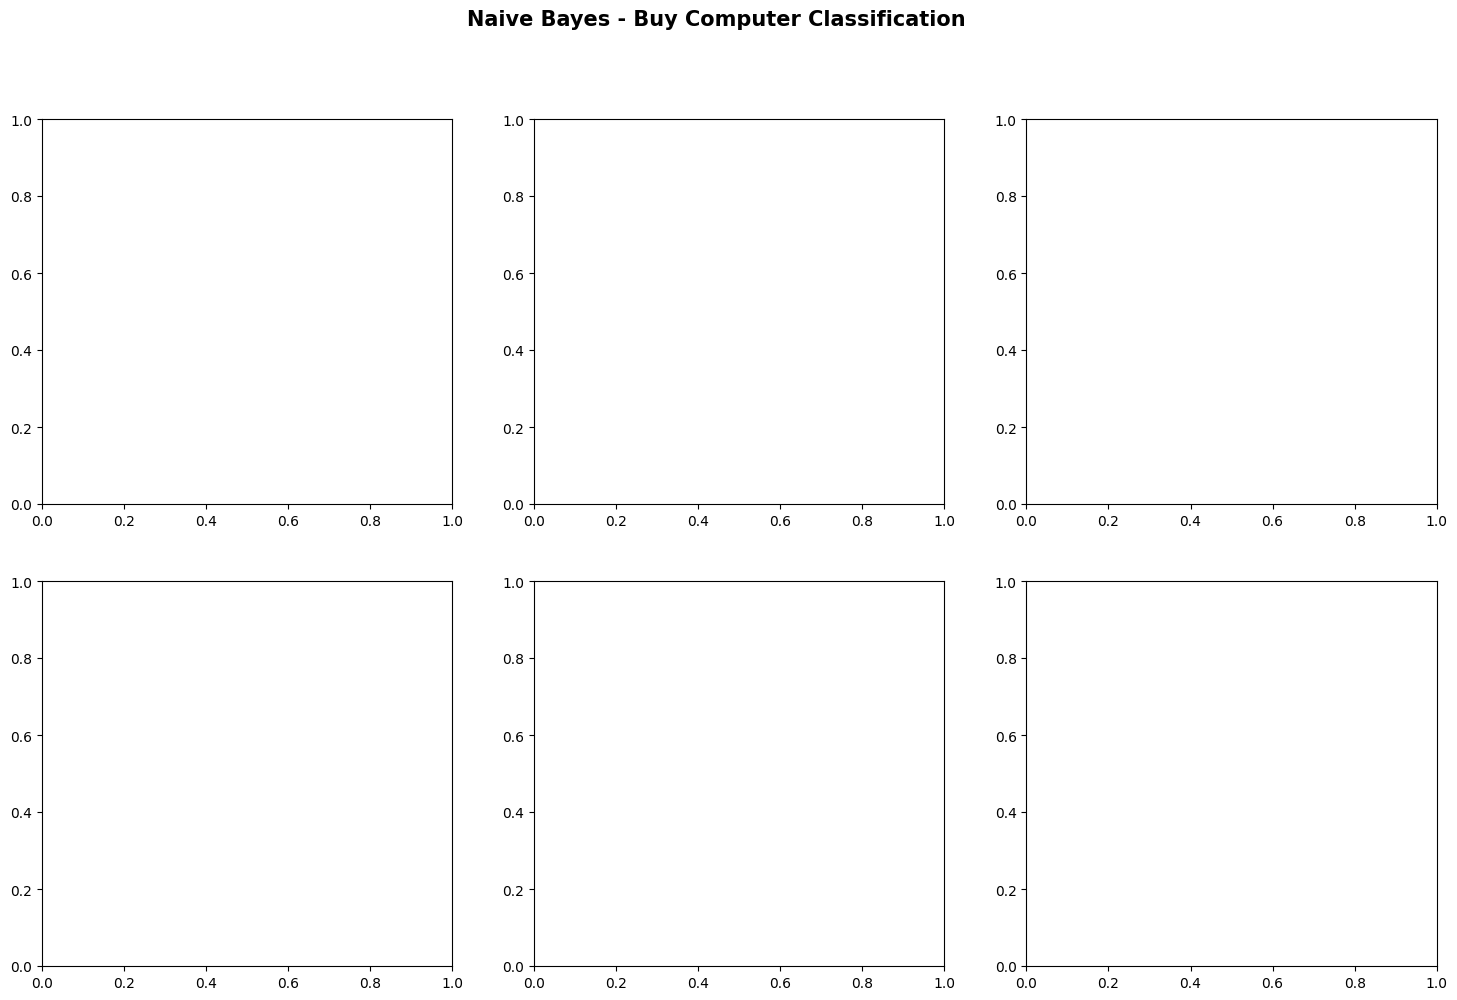

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

#----------plots--------------------------------------------------------
fig, axes = plt.subplots(2,3, figsize=(18,11))
fig.suptitle("Naive Bayes - Buy Computer Classification", fontsize=15, fontweight="bold")

#1. Class Distribution
counts = df['buys_computer'].value_counts()
axes[0,0].bar(counts.index, counts.values, color=['#2ecc71', '#e74c3c'] if counts.index[0] == 'Yes' else ['#e74c3c', '#2ecc71'], edgecolor='black', width=0.4)
axes[0,0].set_title("1. Class Distribution")
axes[0,0].set_xlabel("Buys Computer")
axes[0,0].set_ylabel("Count")

#2. Confusion Matrix
cm = confusion_matrix(y, model.predict(x))
sns.heatmap(cm, annot=True, cmap='Blues', fmt='g', ax=axes[0,1])
axes[0,1].set_title("2. Confusion Matrix")
axes[0,1].set_xlabel("Predicted")
axes[0,1].set_ylabel("Actual")

#3. Prediction Probabilities (Grouped Bar)
tc_labels = [f"TC{i+1}" for i in range(len(test))]
x_axis = np.arange(len(tc_labels))
width = 0.3

prob_no = []
prob_yes = []
for t in test:
    row = [[
        le['age'].transform([t[0].title()])[0],
        le['income'].transform([t[1].title()])[0],
        le['student'].transform([t[2].title()])[0],
        le['credit_rating'].transform([t[3].title()])[0]
    ]]
    prob = model.predict_proba(row)[0]
    prob_no.append(prob[0])
    prob_yes.append(prob[1])

axes[0,2].bar(x_axis - width/2, prob_no, width, label='p(No)', color='#e74c3c', edgecolor='black')
axes[0,2].bar(x_axis + width/2, prob_yes, width, label='p(Yes)', color='#2ecc71', edgecolor='black')
axes[0,2].set_title("3. Prediction Probabilities")
axes[0,2].set_xticks(x_axis)
axes[0,2].set_xticklabels(tc_labels)
axes[0,2].set_ylabel("Probability")
axes[0,2].set_ylim(0, 1.1)
axes[0,2].legend()

#4. Age vs buys_computer
age_counts = df.groupby(['age', 'buys_computer']).size().unstack(fill_value=0)
age_counts.plot(kind='bar', ax=axes[1,0], color=['#e74c3c', '#2ecc71'], edgecolor='black', rot=0)
axes[1,0].set_title("4. Age vs Buys Computer")
axes[1,0].set_xlabel("Age")
axes[1,0].set_ylabel("Count")
axes[1,0].legend(title="Buys Computer")

#5. Income vs BuysComputer
inc_counts = df.groupby(['income', 'buys_computer']).size().unstack(fill_value=0)
inc_counts.plot(kind='bar', ax=axes[1,1], color=['#e74c3c', '#2ecc71'], edgecolor='black', rot=0)
axes[1,1].set_title("5. Income vs Buys Computer")
axes[1,1].set_xlabel("Income")
axes[1,1].set_ylabel("Count")
axes[1,1].legend(title="Buys Computer")

#6. Pie Chart - Final predictions
pred_counts = pd.Series(y_pred).value_counts()
# Mapping encoded indices back to labels for proper plot representation
pred_counts.index = le['buys_computer'].inverse_transform(pred_counts.index)
colors_pred = ['#2ecc71' if l == 'Yes' else '#e74c3c' for l in pred_counts.index]
axes[1,2].pie(pred_counts, labels=pred_counts.index, colors=colors_pred, autopct='%1.1f%%', startangle=90, wedgeprops={'edgecolor': 'black'})
axes[1,2].set_title("6. Train Set Predictions")

plt.tight_layout()
plt.show()
